In [9]:
#Importing necessary libraries and loading the dataset
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns
import numpy as np

df = pd.read_excel('Catcher_Analytics_2026_.xlsx')
df.head()


,Unnamed: 0,Name,Team,Pos,G,GS,Inn,FRV,BA,OBP,SLG,OPS,OPS+,WAR,Rbat,Throwing,Blocking,Framing,2026 Salary
0,1,J.T. Realmuto,PHI,C,132,132,1151.1,-5,0.257,0.315,0.384,0.700,92,2.5,-7,4,-1,-8,15000000
1,2,William Contreras,MIL,C,128,128,1111.2,3,0.260,0.355,0.399,0.754,111,3.9,13,2,1,1,9400000
2,3,Cal Raleigh,SEA,C,121,119,1072.0,7,0.247,0.359,0.589,0.948,167,7.4,50,1,-1,7,12666666
3,4,Patrick Bailey,SFG,C,132,114,1029.2,31,0.222,0.277,0.325,0.602,72,1.1,-16,5,1,25,810000
4,5,Dillon Dingler,DET,C,118,113,1011.2,12,0.278,0.327,0.425,0.752,108,3.1,5,2,2,7,834900


In [10]:
#Renaming columns, creating new variables, and preparing the dataset 
df = df.drop(columns=['Unnamed: 0'])
df['Last_Name'] = df['Name'].str.split().str[-1]
df['Physical_Runs'] = df['Blocking'] + df['Throwing']
df['Salary_M'] = df['2026 Salary'] / 1_000_000
df['Human_Total_Defense'] = df['Throwing'] + df['Framing'] + df['Blocking']
df['Retained_Framing'] = (df['Framing'] * 0.45)
df['Lost_Framing'] = (df['Framing'] * 0.55)
df['ABS_Total_Defense'] = df['Physical_Runs'] + df['Retained_Framing']
df['Offensive_Value'] = df['Rbat']
df['Total_ABS_Value'] = (df['Offensive_Value'] + df['Blocking'] + df['Throwing'] + (df['Retained_Framing']))
df['Total_Human_Value'] = (df['Offensive_Value'] + df['Blocking'] + df['Throwing'] + (df['Framing']))
df['ABS_Value_per_Million'] = df['Total_ABS_Value'] / df['Salary_M']
pd.set_option('display.max_columns', None)
df.head(20)


,Name,Team,Pos,G,GS,Inn,FRV,BA,OBP,SLG,OPS,OPS+,WAR,Rbat,Throwing,Blocking,Framing,2026 Salary,Last_Name,Physical_Runs,Salary_M,Human_Total_Defense,Retained_Framing,Lost_Framing,ABS_Total_Defense,Offensive_Value,Total_ABS_Value,Total_Human_Value,ABS_Value_per_Million
0,J.T. Realmuto,PHI,C,132,132,1151.1,-5,0.257,0.315,0.384,0.700,92,2.5,-7,4,-1,-8,15000000,Realmuto,3,15.000000,-5,-3.60,-4.40,-0.60,-7,-7.60,-12,-0.506667
1,William Contreras,MIL,C,128,128,1111.2,3,0.260,0.355,0.399,0.754,111,3.9,13,2,1,1,9400000,Contreras,3,9.400000,4,0.45,0.55,3.45,13,16.45,17,1.750000
2,Cal Raleigh,SEA,C,121,119,1072.0,7,0.247,0.359,0.589,0.948,167,7.4,50,1,-1,7,12666666,Raleigh,0,12.666666,7,3.15,3.85,3.15,50,53.15,57,4.196053
3,Patrick Bailey,SFG,C,132,114,1029.2,31,0.222,0.277,0.325,0.602,72,1.1,-16,5,1,25,810000,Bailey,6,0.810000,31,11.25,13.75,17.25,-16,1.25,15,1.543210
4,Dillon Dingler,DET,C,118,113,1011.2,12,0.278,0.327,0.425,0.752,108,3.1,5,2,2,7,834900,Dingler,4,0.834900,11,3.15,3.85,7.15,5,12.15,16,14.552641
5,Austin Wells,NYY,C,122,112,1001.0,12,0.219,0.275,0.436,0.712,94,0.1,-4,0,0,12,866200,Wells,0,0.866200,12,5.40,6.60,5.40,-4,1.40,8,1.616255
6,Yainer Diaz,HOU,C,113,111,990.0,-3,0.256,0.284,0.417,0.701,93,2.7,-4,1,0,-3,4500000,Diaz,1,4.500000,-2,-1.35,-1.65,-0.35,-4,-4.35,-6,-0.966667
7,Alejandro Kirk,TOR,C,118,111,965.1,22,0.282,0.348,0.421,0.769,111,2.3,6,0,5,17,8700000,Kirk,5,8.700000,22,7.65,9.35,12.65,6,18.65,28,2.143678
8,Carlos Narváez,BOS,C,112,106,952.0,12,0.241,0.306,0.419,0.726,103,2.6,-2,6,1,5,800000,Narváez,7,0.800000,12,2.25,2.75,9.25,-2,7.25,10,9.062500
9,Bo Naylor,CLE,C,119,106,945.1,0,0.195,0.282,0.379,0.661,83,1.5,-9,1,1,-3,824900,Naylor,2,0.824900,-1,-1.35,-1.65,0.65,-9,-8.35,-10,-10.122439


In [11]:
#Creating a dictionary of MLB team colors for visualization purposes
mlb_team_colors = {
    'ARI': {'primary': '#A71930'},
    'ATL': {'primary': '#13274F'},
    'BAL': {'primary': '#DF4601'},
    'BOS': {'primary': '#BD3039'},
    'CHC': {'primary': '#0E3386'},
    'CHW': {'primary': '#000000'},
    'CIN': {'primary': '#C6011F'},
    'CLE': {'primary': '#00385D'},
    'COL': {'primary': '#33006F'},
    'DET': {'primary': '#182D55'},
    'HOU': {'primary': '#002D62'},
    'KCR': {'primary': '#174885'},
    'LAA': {'primary': '#BA0021'},
    'LAD': {'primary': '#005A9C'},
    'MIA': {'primary': '#000000'},
    'MIL': {'primary': '#0A2351'},
    'MIN': {'primary': '#002B5C'},
    'NYM': {'primary': '#002D72'},
    'NYY': {'primary': '#132448'},
    'ATH': {'primary': '#003831'},
    'PHI': {'primary': '#E81828'},
    'PIT': {'primary': '#000000'},
    'SFG': {'primary': '#FD5A1E'},
    'SEA': {'primary': '#0C2C56'},
    'STL': {'primary': '#C41E3A'},
    'TEX': {'primary': '#003278'},
    'TOR': {'primary': '#134A8E'},
    'WSN': {'primary': '#AB0003'},
    '2Tms': {'primary': '#000000'}
}


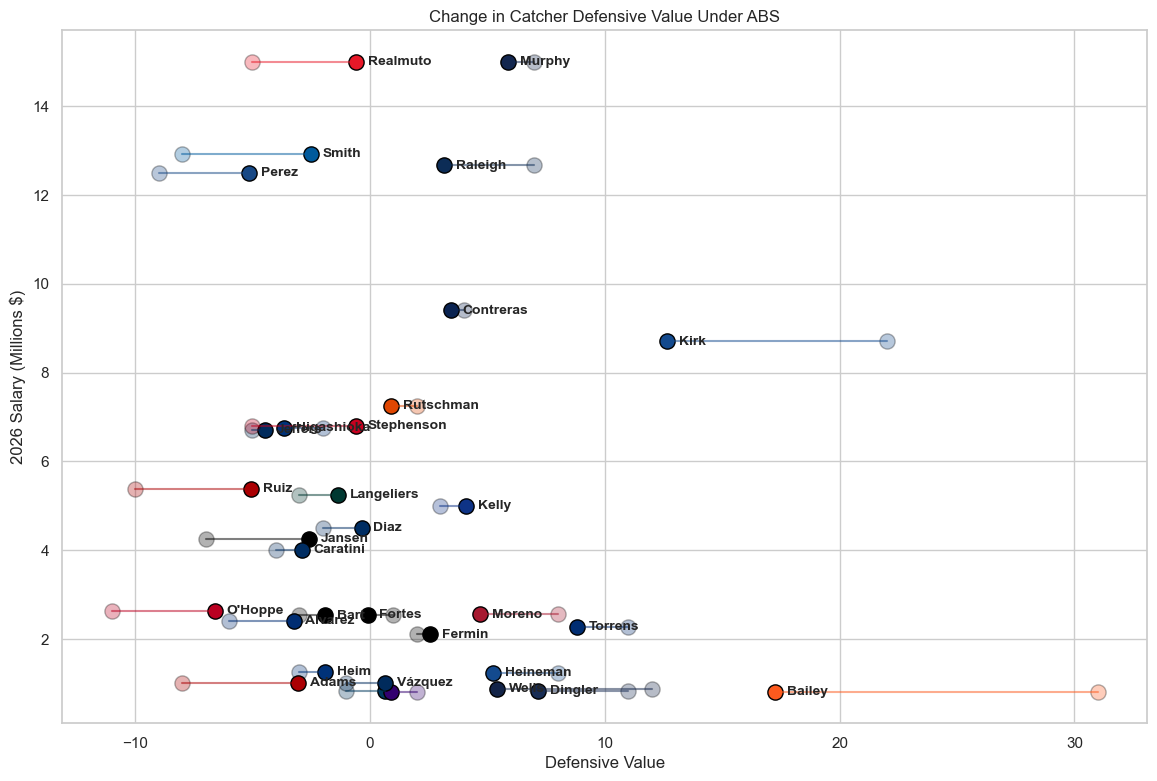

In [12]:
#Building defesive value scatter plot comparing ABS and human defensive values. Filtering out players making league minimum for clearer results.
df_filtered = df[df['Salary_M'] > 0.8].copy()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 9))


for i, row in df_filtered.iterrows():
    team_color = mlb_team_colors.get(row['Team'], {'primary': '#000000', 'secondary': '#FFFFFF'})
    player_label = row['Last_Name']
    plt.scatter(row['Human_Total_Defense'], row['Salary_M'], color=team_color['primary'], s=120, alpha=0.3, edgecolors='black')
    plt.scatter(row['ABS_Total_Defense'], row['Salary_M'], color=team_color['primary'], s=120, edgecolors='black')
    plt.plot([row['Human_Total_Defense'], row['ABS_Total_Defense']], [row['Salary_M'], row['Salary_M']], 
             color=team_color['primary'], linestyle='-', alpha=0.5)

    if row['Salary_M'] > 0.85 or row['ABS_Total_Defense'] > df_filtered['ABS_Total_Defense'].quantile(0.75):
         plt.text(row['ABS_Total_Defense'] + 0.5, row['Salary_M'], row['Last_Name'], 
                  fontsize=10, weight='bold', va='center')

plt.title('Change in Catcher Defensive Value Under ABS')
plt.xlabel('Defensive Value')
plt.ylabel('2026 Salary (Millions $)')
plt.show()

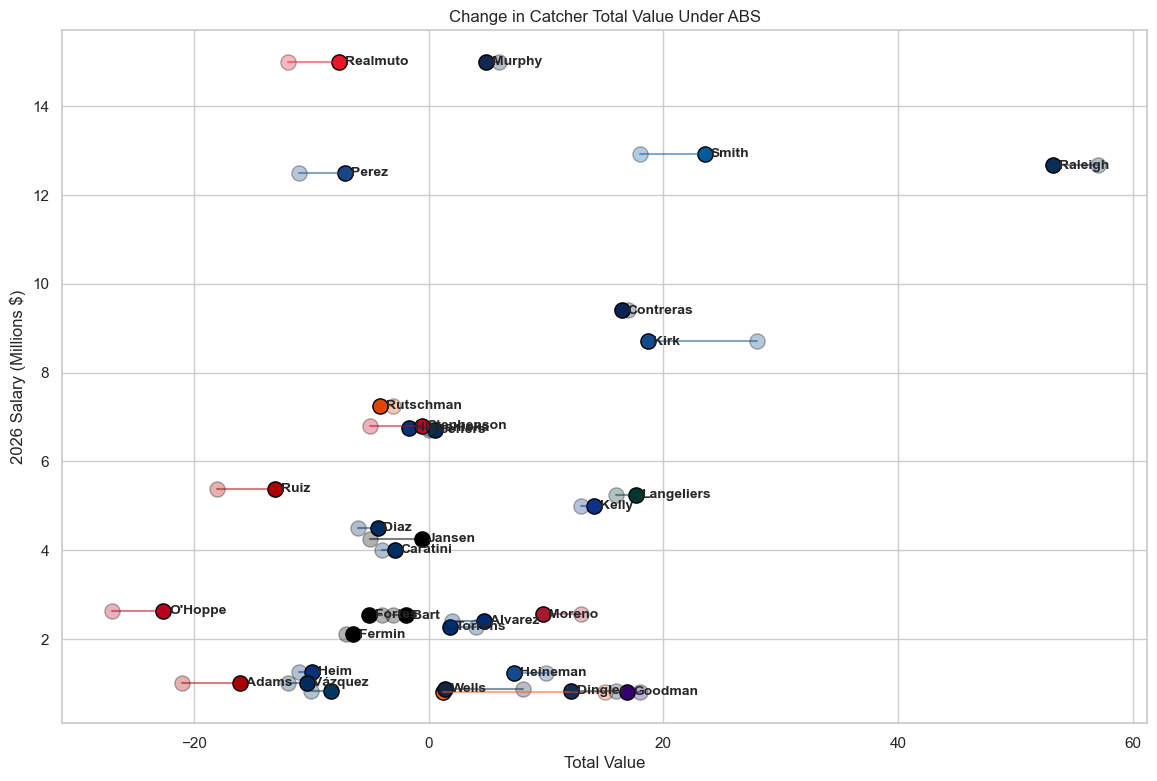

In [13]:
#Building total value scatter plot comparing ABS and human defensive values combinded with offensive values. Filtering out players making league minimum for clearer results.
df_filtered = df[df['Salary_M'] > 0.8].copy()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 9))


for i, row in df_filtered.iterrows():
    team_color = mlb_team_colors.get(row['Team'], {'primary': '#000000', 'secondary': '#FFFFFF'})
    player_label = row['Last_Name']
    plt.scatter(row['Total_Human_Value'], row['Salary_M'], color=team_color['primary'], s=120, alpha=0.3, edgecolors='black')
    plt.scatter(row['Total_ABS_Value'], row['Salary_M'], color=team_color['primary'], s=120, edgecolors='black')
    plt.plot([row['Total_Human_Value'], row['Total_ABS_Value']], [row['Salary_M'], row['Salary_M']], 
             color=team_color['primary'], linestyle='-', alpha=0.5)

    if row['Salary_M'] > 0.85 or row['Total_ABS_Value'] > df_filtered['Total_ABS_Value'].quantile(0.75):
         plt.text(row['Total_ABS_Value'] + 0.5, row['Salary_M'], row['Last_Name'], 
                  fontsize=10, weight='bold', va='center')

plt.title('Change in Catcher Total Value Under ABS')
plt.xlabel('Total Value')
plt.ylabel('2026 Salary (Millions $)')
plt.show()

In [14]:
#Fit salary regression model to compute expected salary differences
df['Log_Salary'] = np.log(df['Salary_M'])

model_formula = 'Log_Salary ~ Rbat + Blocking + Throwing + Framing + WAR + Inn'
xSalary_model = smf.ols(formula=model_formula, data=df).fit()
print(xSalary_model.summary())

df['xSalary'] = np.exp(xSalary_model.predict(df))


df['Salary_Diff'] = df['Salary_M'] - df['xSalary']

summary = df[['Last_Name', 'Team', 'Salary_M', 'xSalary', 'Salary_Diff', 'Rbat', 'WAR', 'Inn', 'Framing', 'Throwing', 'Blocking']]



                            OLS Regression Results                            
Dep. Variable:             Log_Salary   R-squared:                       0.230
Model:                            OLS   Adj. R-squared:                  0.094
Method:                 Least Squares   F-statistic:                     1.693
Date:                Sun, 10 May 2026   Prob (F-statistic):              0.153
Time:                        17:18:05   Log-Likelihood:                -54.063
No. Observations:                  41   AIC:                             122.1
Df Residuals:                      34   BIC:                             134.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.3677      0.702      0.524      0.6

Top 10 Most Overpaid Catchers (Actual vs. Expected):
     Last_Name Team  Salary_M   xSalary  Salary_Diff  Rbat  WAR     Inn  \
25      Murphy  ATL    15.000  2.394211    12.605789    -1  2.4   633.0   
0     Realmuto  PHI    15.000  4.466684    10.533316    -7  2.5  1151.1   
18       Perez  KCR    12.500  3.437244     9.062756    -2  0.4   761.2   
7         Kirk  TOR     8.700  1.868295     6.831705     6  2.3   965.1   
33   Rutschman  BAL     7.250  1.527956     5.722044    -5  1.9   573.1   
27  Higashioka  TEX     6.750  1.526422     5.223578     2  1.6   604.1   
1    Contreras  MIL     9.400  5.007216     4.392784    13  3.9  1111.2   
21     Jeffers  MIN     6.700  2.348712     4.351288     5  1.2   699.2   
30  Stephenson  CIN     6.800  3.156073     3.643927     0  1.3   586.0   
34        Ruiz  WSN     5.375  2.446571     2.928429    -8  0.8   557.0   

    Framing  Throwing  Blocking  
25        2         3         2  
0        -8         4        -1  
18       -7        

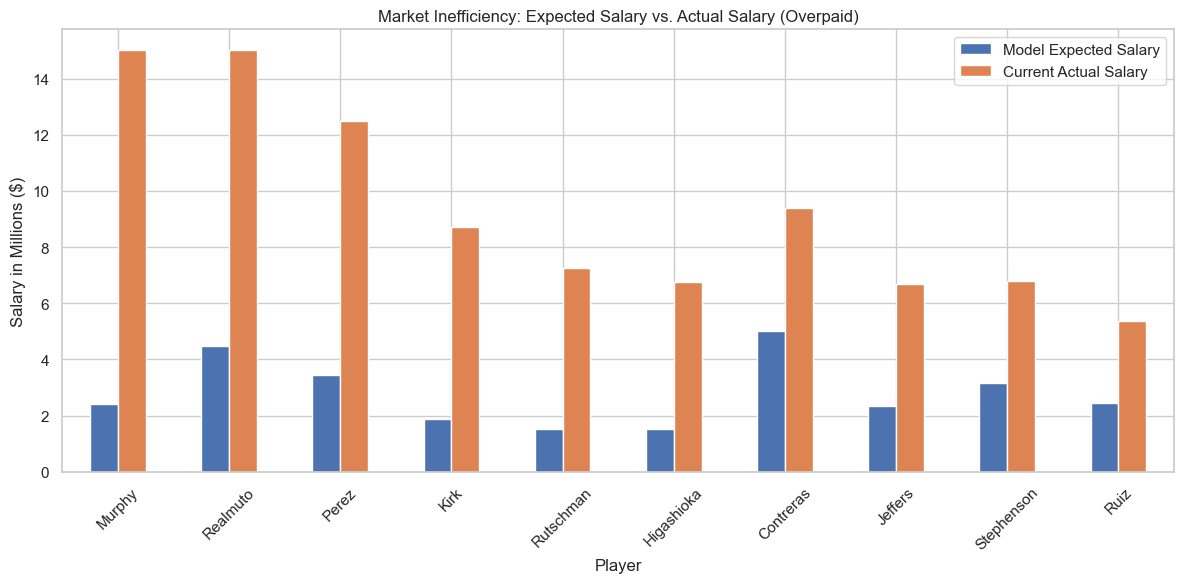

In [15]:
#Plot top overpaid catchers actual versus expected salary
top_overpaid = summary.sort_values(by='Salary_Diff', ascending=False).head(10)

print("Top 10 Most Overpaid Catchers (Actual vs. Expected):")
print(top_overpaid)

top_overpaid.plot(x='Last_Name', y=['xSalary', 'Salary_M'], kind='bar', figsize=(12, 6))

plt.title('Market Inefficiency: Expected Salary vs. Actual Salary (Overpaid)')
plt.ylabel('Salary in Millions ($)')
plt.xlabel('Player')
plt.legend(['Model Expected Salary', 'Current Actual Salary'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Most Underpaid Catchers (Actual vs. Expected):
   Last_Name  Team  Salary_M   xSalary  Salary_Diff  Rbat  WAR     Inn  \
15   Goodman   COL   0.81000  3.537046    -2.727046    16  3.7   841.1   
19   Baldwin   ATL   0.80000  3.515360    -2.715360    15  3.3   759.2   
8    Narváez   BOS   0.80000  3.148960    -2.348960    -2  2.6   952.0   
32     Quero   CHW   0.78745  2.981997    -2.194547    -2  1.2   579.0   
4    Dingler   DET   0.83490  2.924337    -2.089437     5  3.1  1011.2   
9     Naylor   CLE   0.82490  2.573739    -1.748839    -9  1.5   945.1   
36      Teel   CHW   0.78805  2.392165    -1.604115     9  1.9   501.1   
23     Adams   WSN   1.00000  2.338469    -1.338469   -13  0.4   642.1   
40    Thaiss  2Tms   0.78000  1.841051    -1.061051    -2  1.2   411.2   
29   Alvarez   NYM   2.40000  3.333096    -0.933096     8  1.9   596.0   

    Framing  Throwing  Blocking  
15        2        -1         1  
19       -1        -2         2  
8         5         6        

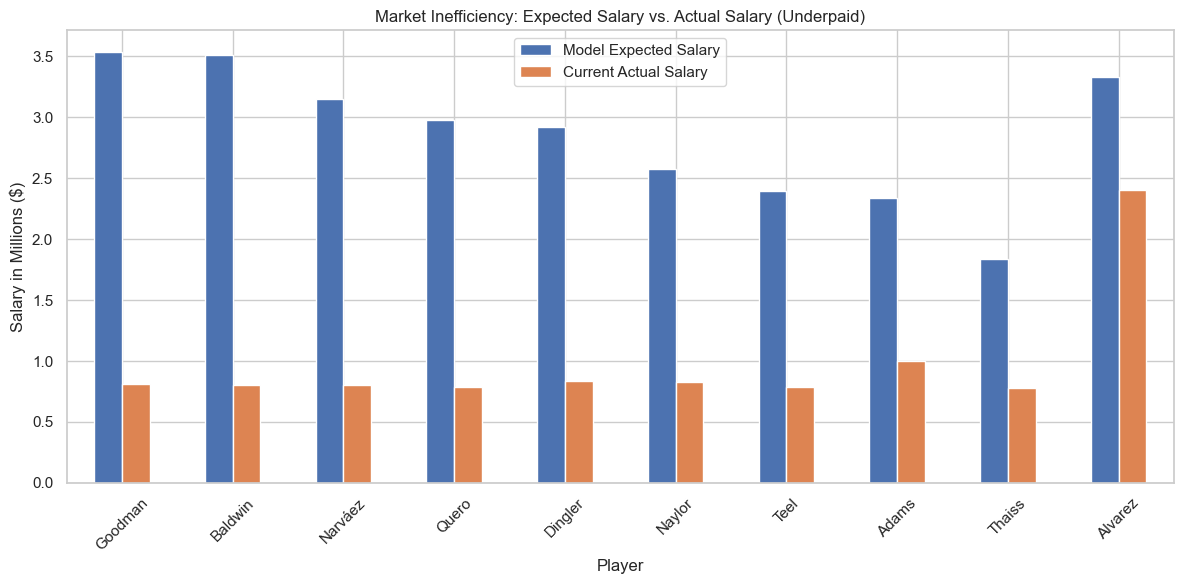

In [16]:
#Plot top underpaid catchers actual versus expected salary
top_underpaid = summary.sort_values(by='Salary_Diff', ascending=True).head(10)
print("Top 10 Most Underpaid Catchers (Actual vs. Expected):")
print(top_underpaid)

top_underpaid.plot(x='Last_Name', y=['xSalary', 'Salary_M'], kind='bar', figsize=(12, 6))

plt.title('Market Inefficiency: Expected Salary vs. Actual Salary (Underpaid)')
plt.ylabel('Salary in Millions ($)')
plt.xlabel('Player')
plt.legend(['Model Expected Salary', 'Current Actual Salary'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()